# Project 02: Data Visualization with Matplotlib & Seaborn

### Guiding Questions & Selected Chart Types
1. **How are total restaurant bills distributed across all meals?** -> *Histogram* (shows frequency distribution of a single continuous variable).
2. **How do tip amounts and average tips compare across different days of the week?** -> *Box Plot & Bar Chart* (compares distributions, medians, outliers, and averages across categorical groups).
3. **Does a larger total bill lead to a larger tip, and does meal time (Lunch vs. Dinner) play a role?** -> *Scatter Plot* (visualizes the relationship between two numerical variables, encoded by color for meal time).
4. **Which numerical variables (`total_bill`, `tip`, `size`) move together most strongly?** -> *Annotated Correlation Heatmap* (quantifies linear relationships across all numeric variables).

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_theme(style="whitegrid", palette="colorblind")
tips = sns.load_dataset("tips")
print("Dataset Shape:", tips.shape)
display(tips.head())
display(tips.describe().round(2))

Dataset Shape: (244, 7)


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


,total_bill,tip,size
count,244.00,244.00,244.00
mean,19.79,3.00,2.57
std,8.90,1.38,0.95
min,3.07,1.00,1.00
25%,13.35,2.00,2.00
50%,17.80,2.90,2.00
75%,24.13,3.56,3.00
max,50.81,10.00,6.00


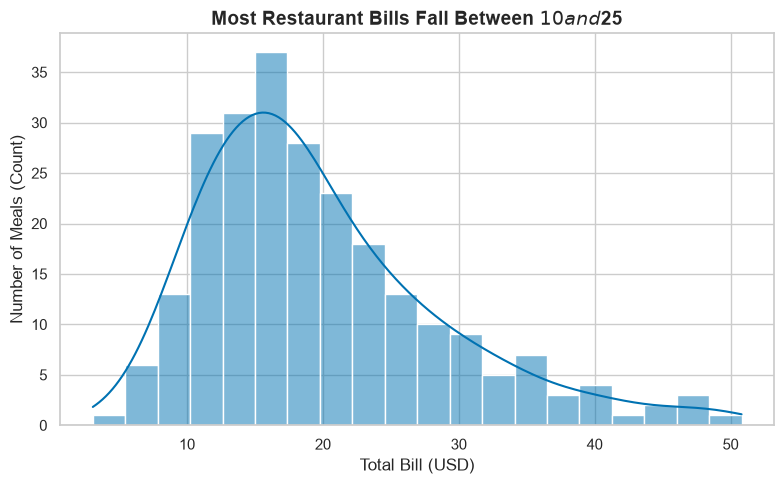

In [2]:
plt.figure(figsize=(8, 5))
sns.histplot(data=tips, x="total_bill", bins=20, kde=True, color="#0072B2")
plt.title("Most Restaurant Bills Fall Between $10 and $25", fontsize=14, fontweight="bold")
plt.xlabel("Total Bill (USD)", fontsize=12)
plt.ylabel("Number of Meals (Count)", fontsize=12)
plt.tight_layout()
plt.show()

**Takeaway 1 (Histogram):** Most restaurant bills are right-skewed and fall between **$10 and $25 USD** (median of $17.80 and mean of $19.79), with very few large bills exceeding $40 USD.

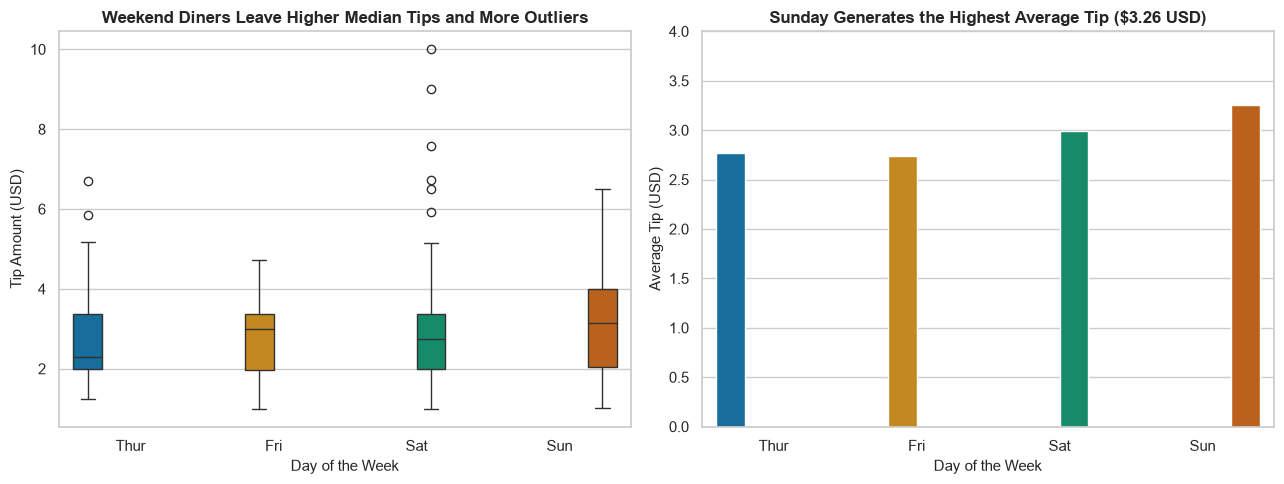

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=tips, x="day", y="tip", hue="day", palette="colorblind", legend=False, ax=ax[0])
ax[0].set_title("Weekend Diners Leave Higher Median Tips and More Outliers", fontsize=12, fontweight="bold")
ax[0].set_xlabel("Day of the Week", fontsize=11)
ax[0].set_ylabel("Tip Amount (USD)", fontsize=11)
sns.barplot(data=tips, x="day", y="tip", hue="day", palette="colorblind", errorbar=None, legend=False, ax=ax[1])
ax[1].set_title("Sunday Generates the Highest Average Tip ($3.26 USD)", fontsize=12, fontweight="bold")
ax[1].set_xlabel("Day of the Week", fontsize=11)
ax[1].set_ylabel("Average Tip (USD)", fontsize=11)
ax[1].set_ylim(0, 4.0)
plt.tight_layout()
plt.show()

**Takeaway 2 (Box Plot & Bar Chart):** Tip amounts are higher on weekends, with **Sunday** recording the highest average tip (**$3.26 USD**) and **Saturday** exhibiting the highest single-tip outliers (up to **$10.00 USD**), compared to **$2.77 USD** on Thursdays.

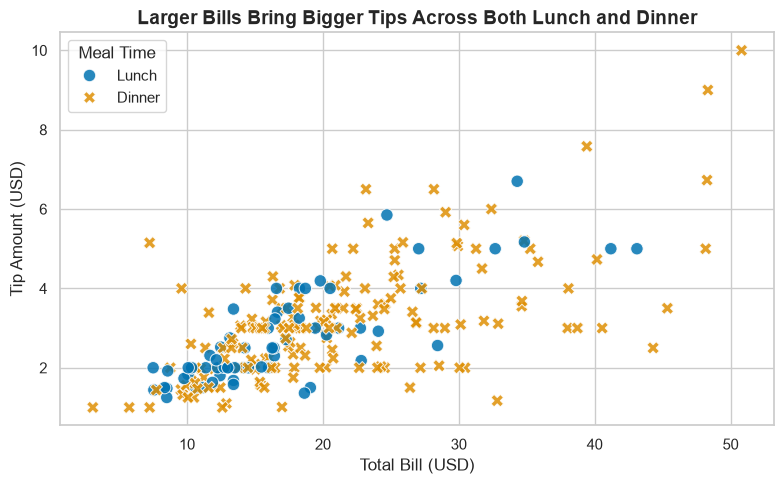

In [4]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=tips,
    x="total_bill",
    y="tip",
    hue="time",
    style="time",
    palette="colorblind",
    s=80,
    alpha=0.85
)
plt.title("Larger Bills Bring Bigger Tips Across Both Lunch and Dinner", fontsize=14, fontweight="bold")
plt.xlabel("Total Bill (USD)", fontsize=12)
plt.ylabel("Tip Amount (USD)", fontsize=12)
plt.legend(title="Meal Time")
plt.tight_layout()
plt.show()

**Takeaway 3 (Scatter Plot):** There is a clear positive linear relationship where bigger bills consistently bring bigger tips, with **Dinner** meals accounting for the vast majority of bills above $30 USD and tips above $5 USD.

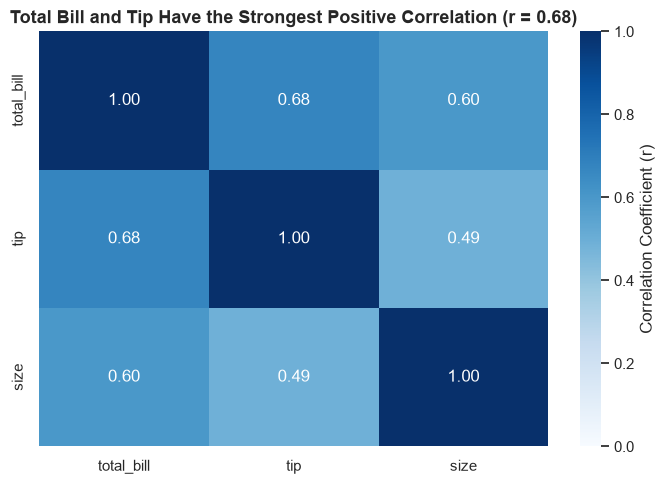

In [5]:
plt.figure(figsize=(7, 5))
corr_matrix = tips.select_dtypes("number").corr()
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    cbar_kws={"label": "Correlation Coefficient (r)"}
)
plt.title("Total Bill and Tip Have the Strongest Positive Correlation (r = 0.68)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

**Takeaway 4 (Correlation Heatmap):** The strongest relationship among the numerical variables is between **`total_bill` and `tip` (`r = 0.68`)**, followed by **`total_bill` and party `size` (`r = 0.60`)**, while party `size` and `tip` have a moderate correlation (`r = 0.49`).

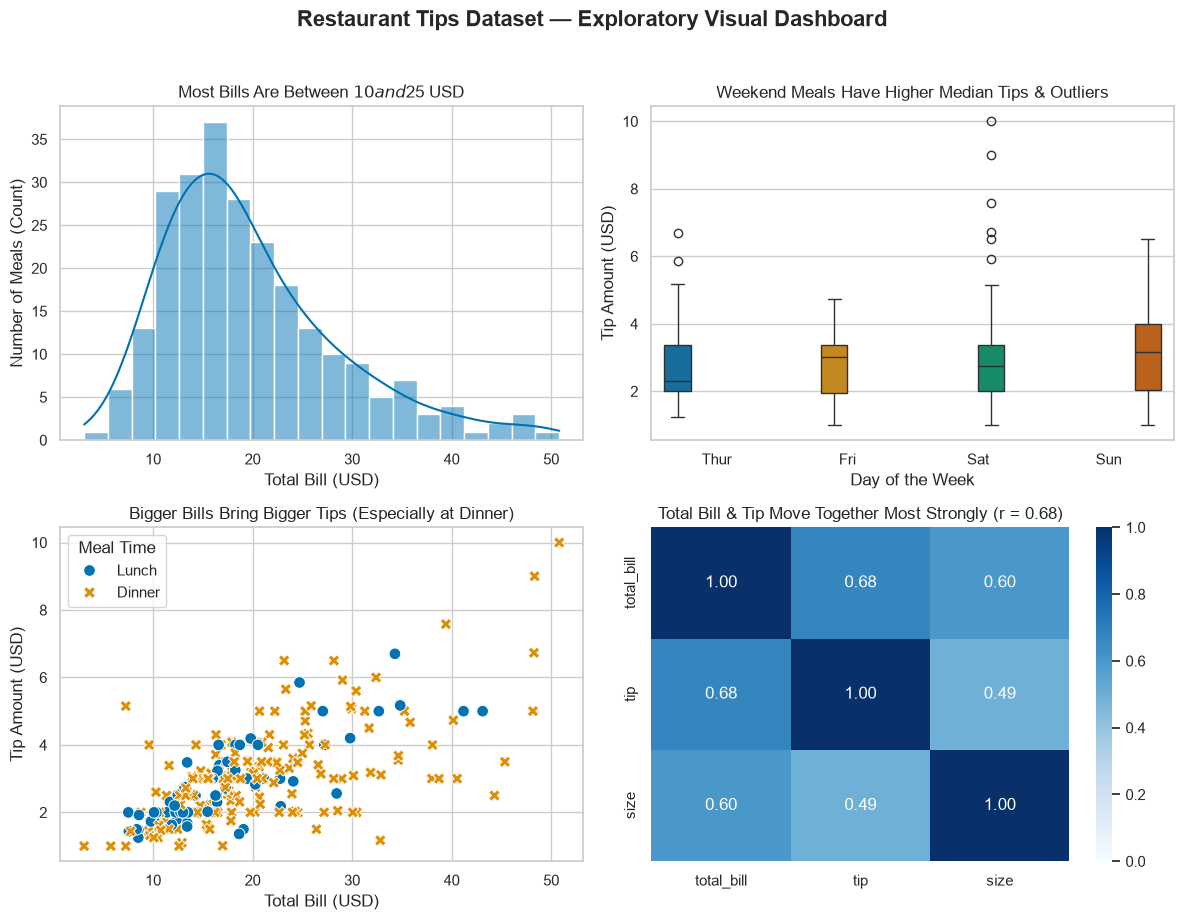

Saved dashboard image successfully as 'tips_overview.png' at 150 DPI.


In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
sns.histplot(tips["total_bill"], bins=20, kde=True, color="#0072B2", ax=axes[0, 0])
axes[0, 0].set(
    title="Most Bills Are Between $10 and $25 USD",
    xlabel="Total Bill (USD)",
    ylabel="Number of Meals (Count)"
)
sns.boxplot(data=tips, x="day", y="tip", hue="day", palette="colorblind", legend=False, ax=axes[0, 1])
axes[0, 1].set(
    title="Weekend Meals Have Higher Median Tips & Outliers",
    xlabel="Day of the Week",
    ylabel="Tip Amount (USD)"
)
sns.scatterplot(data=tips, x="total_bill", y="tip", hue="time", style="time", palette="colorblind", s=70, ax=axes[1, 0])
axes[1, 0].set(
    title="Bigger Bills Bring Bigger Tips (Especially at Dinner)",
    xlabel="Total Bill (USD)",
    ylabel="Tip Amount (USD)"
)
axes[1, 0].legend(title="Meal Time")
sns.heatmap(
    tips.select_dtypes("number").corr(),
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    ax=axes[1, 1]
)
axes[1, 1].set_title("Total Bill & Tip Move Together Most Strongly (r = 0.68)")
plt.suptitle("Restaurant Tips Dataset — Exploratory Visual Dashboard", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("tips_overview.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved dashboard image successfully as 'tips_overview.png' at 150 DPI.")

### Summary of Visual Takeaways
1. **Bill Distribution (Histogram):** Most meals cost between **$10 and $25 USD** (median $17.80 USD), with a right-skewed tail extending up to $50.81 USD.
2. **Tips by Day (Box Plot & Bar Chart):** Sunday has the highest average tip (**$3.26 USD**) and median tip (**$3.15 USD**), whereas Saturday shows the widest spread and highest individual tip outliers (up to **$10.00 USD**).
3. **Bill vs. Tip Relationship (Scatter Plot):** Larger bills consistently generate higher tips, with Dinner shifts accounting for most high-value bills and tips.
4. **Numeric Correlations (Heatmap):** `total_bill` and `tip` show the strongest positive linear relationship (**`r = 0.68`**), while `total_bill` and party `size` also correlate strongly (**`r = 0.60`**).